DC OPF_IEEE 39-bus system

In [1]:
#import libraries

from pandapower.create import (
    create_gen,
    create_load,
    create_poly_cost
)

from pandapower.run import runopp, rundcopp
from pandapower import from_pickle
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
from pandapower.runpm import runpm_ac_opf, runpm_dc_opf

In [2]:
#load IEEE 39-bus system
def load_network():
    return from_pickle("ieee118bus.p")

In [3]:
#plot results

def opf_results(results):
    %matplotlib inline
    plt.rc('xtick', labelsize=9)
    plt.rc('ytick', labelsize=9)
    plt.rc('legend', fontsize=9)
    plt.rc('axes', labelsize=10)
    plt.rcParams['font.size'] = 10

    sns.set_style("whitegrid", {'axes.grid' : False})
    fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(10,5))
    ax = axes
    sns.boxplot(results.installed_mw, width=.1, ax=ax, orient="v")
    ax.set_ylabel("Installed Active Power [MW]")

In [4]:
def dcopf_gen():
    results = pd.DataFrame(columns=["installed_mw"])
    iterations = 118

    for i in range(iterations):
        #load new network
        net = load_network()

        #add new generator at bus i
        new_gen = create_gen(net, name="New Gen", bus=net.load.bus.values[i], p_mw=0, min_p_mw=0, max_p_mw=8000, min_q_mvar=-6000, max_q_mvar=6000, vm_pu=1.025, controllable=True)

        #define cost function
        costeg = create_poly_cost(net, element=len(net.gen.bus.values)-1, et='gen', cp1_eur_per_mw=-1)

        #run DC OPF
        rundcopp(net, verbose=False, delta=1e-16)

        print("Results for hosting capacity for new generation at bus " + str(net.load.bus.values[i]))

        #print new generation
        print("New generation at bus " + str(net.load.bus.values[i]) + " = " + str(round(net.res_gen.p_mw[len(net.gen.bus.values)-1],2)) + " MW")
        
        #print ext_grid power
        #for j in range(len(net.res_ext_grid)):
        #    print("Grid Power: " + str(round(net.res_ext_grid.p_mw[j],2)))

        #print generator power
        #for j in range(len(net.res_gen)):
        #    print(net.gen.name[j] + " power = " + str(round(net.res_gen.p_mw[j],2)) + " MW")

        #print line loading
        #for j in range(len(net.res_line)):
        #    print(net.line.name[j] + " loading = " + str(round(net.res_line.loading_percent[j],2)) + "%")

        #print trafo loading
        #for j in range(len(net.res_trafo)):
        #    print(net.trafo.name[j] + " loading = " + str(round(net.res_trafo.loading_percent[j],2)) + "%")

        print("-----------------------------------------------------------------------------------")
        results.loc[i] = round(net.res_gen.p_mw[len(net.gen.bus.values)-1],2)
    
    return results

In [5]:
def acopf_load():
    results = pd.DataFrame(columns=["installed_mw"])
    iterations = 118
    
    for i in range(iterations):
        #load new network
        net = load_network()

        #add new generator at bus i
        new_load = create_load(net, name="New Load", bus=net.load.bus.values[i], p_mw=0, min_p_mw=0, max_p_mw=200, min_q_mvar=-150, max_q_mvar=150, in_service=True, type='wye', controllable=True)

        #define cost function
        #costeg = create_poly_cost(net, element=0, et='ext_grid', cp1_eur_per_mw=1)
        #costgnew = create_poly_cost(net, element=2, et='gen', cp1_eur_per_mw=1)
        costload = create_poly_cost(net, element=len(net.load.bus.values)-1, et='load', cp1_eur_per_mw=-1)

        #run AC OPF
        runpm_ac_opf(net, verbose=False, delta=1e-16, init="pf")

        print("Results for hosting capacity for new generation at bus " + str(net.load.bus.values[i]))

        #print ext_grid power
        #for j in range(len(net.res_ext_grid)):
        #    print("Grid Power: " + str(round(net.res_ext_grid.p_mw[j],2)))

        #print generator power
        #for j in range(len(net.res_gen)):
        #    print(net.gen.name[j] + " power = " + str(round(net.res_gen.p_mw[j],2)) + " MW")

        #print line loading
        #for j in range(len(net.res_line)):
        #    print(net.line.name[j] + " loading = " + str(round(net.res_line.loading_percent[j],2)) + "%")

        #print trafo loading
        #for j in range(len(net.res_trafo)):
        #    print(net.trafo.name[j] + " loading = " + str(round(net.res_trafo.loading_percent[j],2)) + "%")

        print("-----------------------------------------------------------------------------------")
        #results.loc[i] = round(net.res_gen.p_mw[2],2)
        results.loc[i] = round(net.res_load.p_mw[len(net.load.bus.values)-1],2)
    
    return results

In [6]:
def dcopf_load():
    results = pd.DataFrame(columns=["installed_mw"])
    iterations = 118

    for i in range(iterations):
        #load new network
        net = load_network()

        #add new generator at bus i
        new_load = create_load(net, name="New Load", bus=net.load.bus.values[i], p_mw=0, q_mvar=0, max_p_mw=600, min_p_mw=0, max_q_mvar=450, min_q_mvar=-150, in_service=True, type='wye', controllable=True)

        #define cost function
        costload = create_poly_cost(net, element=len(net.load.bus.values)-1, et='load', cp1_eur_per_mw=-1)

        #run DC OPF
        rundcopp(net, verbose=False, delta=1e-16)

        print("Results for hosting capacity for new load at bus " + str(net.load.bus.values[i]))

        #print new load
        print("New load at bus " + str(net.load.bus.values[i]) + " = " + str(round(net.res_load.p_mw[len(net.load.bus.values)-1],2)) + " MW")

        #print ext_grid power
        #for j in range(len(net.res_ext_grid)):
        #    print("Grid Power: " + str(round(net.res_ext_grid.p_mw[j],2)))

        #print generator power
        #for j in range(len(net.res_gen)):
        #    print(net.gen.name[j] + " power = " + str(round(net.res_gen.p_mw[j],2)) + " MW")

        #print line loading
        #for j in range(len(net.res_line)):
        #    print(net.line.name[j] + " loading = " + str(round(net.res_line.loading_percent[j],2)) + "%")

        #print trafo loading
        #for j in range(len(net.res_trafo)):
        #    print(net.trafo.name[j] + " loading = " + str(round(net.res_trafo.loading_percent[j],2)) + "%")

        print("----------------------------------------------------------------------------------")
        results.loc[i] = round(net.res_load.p_mw[len(net.load.bus.values)-1],2)
    
    return results

Hosting Capacity of Generation

In [7]:
#running dc opf of generation
dcopf_gen_results = dcopf_gen()

Results for hosting capacity for new generation at bus 0
New generation at bus 0 = 668.14 MW
-----------------------------------------------------------------------------------
Results for hosting capacity for new generation at bus 1
New generation at bus 1 = 668.27 MW
-----------------------------------------------------------------------------------
Results for hosting capacity for new generation at bus 2
New generation at bus 2 = 668.08 MW
-----------------------------------------------------------------------------------
Results for hosting capacity for new generation at bus 3
New generation at bus 3 = 667.75 MW
-----------------------------------------------------------------------------------
Results for hosting capacity for new generation at bus 4
New generation at bus 4 = 667.73 MW
-----------------------------------------------------------------------------------
Results for hosting capacity for new generation at bus 5
New generation at bus 5 = 668.04 MW
----------------------

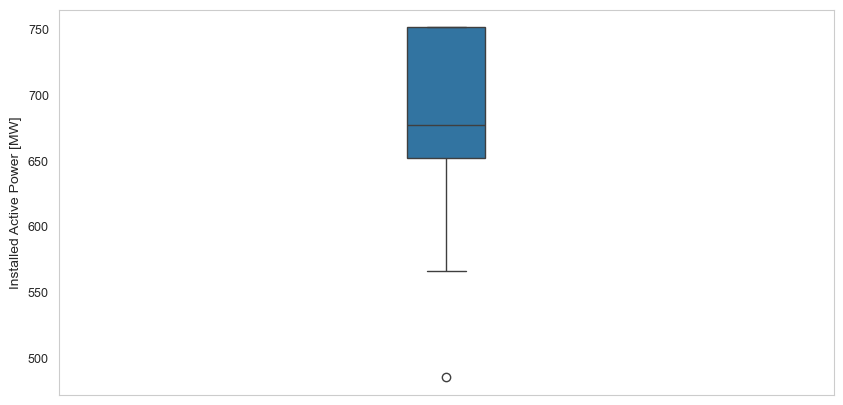

In [8]:
opf_results(dcopf_gen_results)

Hosting Capacity of Consumption

In [9]:
#run dc opf of consumption
dcopf_load_results = dcopf_load()

Results for hosting capacity for new load at bus 0
New load at bus 0 = 348.48 MW
----------------------------------------------------------------------------------
Results for hosting capacity for new load at bus 1
New load at bus 1 = 348.48 MW
----------------------------------------------------------------------------------
Results for hosting capacity for new load at bus 2
New load at bus 2 = 348.48 MW
----------------------------------------------------------------------------------
Results for hosting capacity for new load at bus 3
New load at bus 3 = 348.48 MW
----------------------------------------------------------------------------------
Results for hosting capacity for new load at bus 4
New load at bus 4 = 348.48 MW
----------------------------------------------------------------------------------
Results for hosting capacity for new load at bus 5
New load at bus 5 = 348.48 MW
----------------------------------------------------------------------------------
Results for host

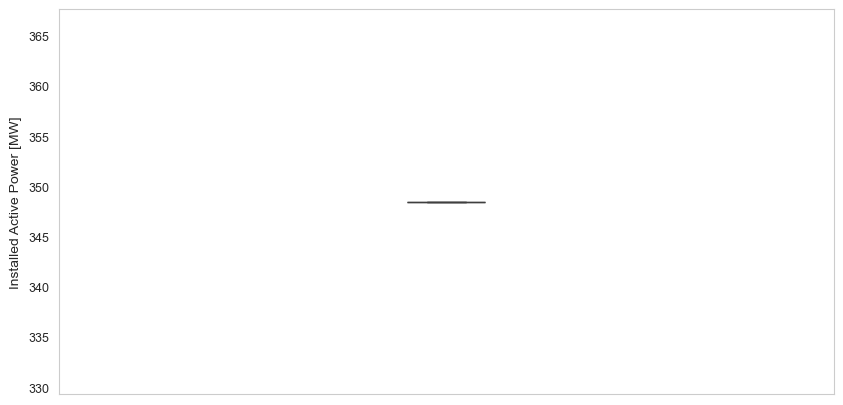

In [10]:
opf_results(dcopf_load_results)

In [11]:
#acopf_load()